# COU 07506 Digital Signal Processing Week 04: z-Transform Laboratory - Poles, Zeros and Stability
**Name:** David Charles Mpendahaki  
**Class:** BEng24COE  
**Group:** [07]  
**Registration No.:** 240242411775  
**Date:** November 25, 2026  
**Instructor checkpoints signed:** [ ] 4  

---

## Pre-lab Preparation
1. **(a) Find the poles of $H(z) = \frac{1}{1 - 0.9z^{-1} + 0.81z^{-2}}$ and decide whether it is stable:**
   * Characteristic equation: $z^2 - 0.9z + 0.81 = 0$
   * Using the quadratic formula:
     $$z = \frac{0.9 \pm \sqrt{(-0.9)^2 - 4(1)(0.81)}}{2} = \frac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = 0.45 \pm j\,0.7794$$
   * **Pole magnitude:** $|p| = \sqrt{0.45^2 + 0.7794^2} = \sqrt{0.81} = \mathbf{0.9}$ (at angles $\theta = \pm 60^\circ = \pm \frac{\pi}{3}\text{ rad}$).
   * **Stability:** Since $|p| = 0.9 < 1$ (all poles lie strictly inside the unit circle), the causal system is **BIBO stable**.

2. **(b) Partial-fraction expansion of $X(z) = \frac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})}$:**
   $$X(z) = \frac{A}{1 - 0.5z^{-1}} + \frac{B}{1 - 0.25z^{-1}}$$
   * $A = \left.\frac{1}{1 - 0.25z^{-1}}\right|_{z^{-1}=2} = \frac{1}{1 - 0.5} = \mathbf{2}$
   * $B = \left.\frac{1}{1 - 0.5z^{-1}}\right|_{z^{-1}=4} = \frac{1}{1 - 2} = \mathbf{-1}$
   * **Result:** $X(z) = \frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}}$

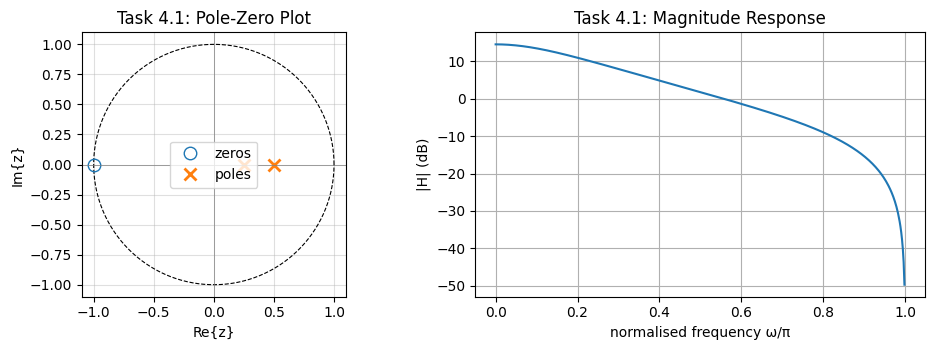

Task 4.1 poles: [0.5  0.25] | stable: True

=== Task 4.2: Inverse z-Transform ===
Pre-lab X(z) residues: [-1.  2.] | poles: [0.25 0.5 ]
X(z) residuez matches lfilter: True

Task 4.1 H(z) residues: [-5.  6.] | poles: [0.25 0.5 ]
Matches h(n) = 6(0.5)^n - 5(0.25)^n: True


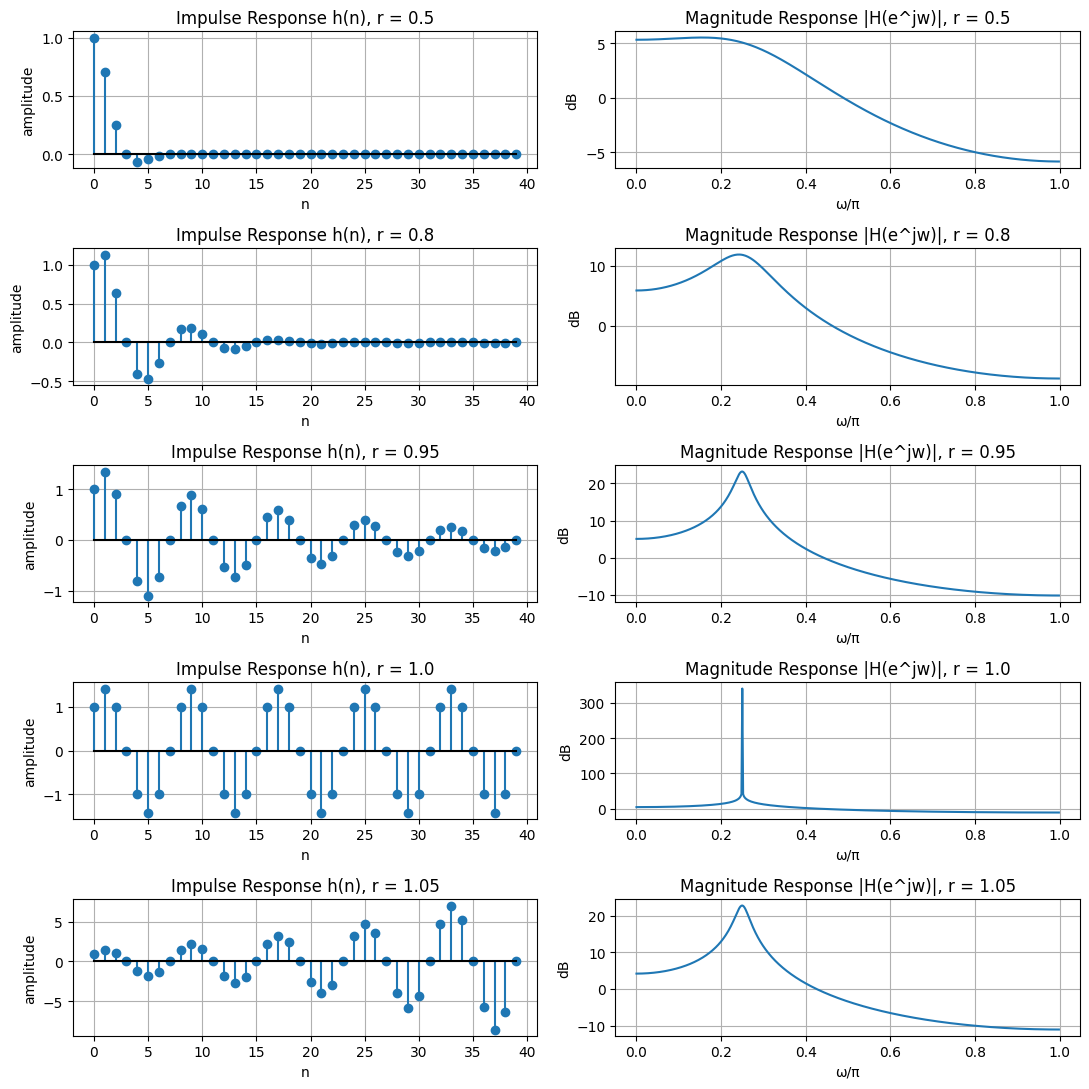

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# ==========================================
# Task 4.1: Pole-Zero Plotting Function
# ==========================================
def zplane(b, a, ax=None, title="Pole-zero plot"):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("Re{z}")
    ax.set_ylabel("Im{z}")
    ax.legend()
    ax.grid(True, alpha=0.4)
    return z, p

b1, a1 = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z1, p1 = zplane(b1, a1, ax1, title="Task 4.1: Pole-Zero Plot")
w, H = signal.freqz(b1, a1, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H) + 1e-12))
ax2.set_title("Task 4.1: Magnitude Response")
ax2.set_xlabel("normalised frequency ω/π")
ax2.set_ylabel("|H| (dB)")
ax2.grid(True)
plt.tight_layout()
plt.show()

print("Task 4.1 poles:", p1, "| stable:", np.all(np.abs(p1) < 1))


# ==========================================
# Task 4.2: Inverse z-Transform with residuez
# ==========================================
print("\n=== Task 4.2: Inverse z-Transform ===")
r_x, p_x, k_x = signal.residuez([1], [1, -0.75, 0.125])
print("Pre-lab X(z) residues:", r_x, "| poles:", p_x)

n = np.arange(10)
x_pf = sum(ri * (pi**n) for ri, pi in zip(r_x, p_x)).real
impulse = np.zeros(10)
impulse[0] = 1.0
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("X(z) residuez matches lfilter:", np.allclose(x_pf, x_lf))

# Repeat for Task 4.1 system: b = [1, 1], a = [1, -0.75, 0.125]
r_h, p_h, k_h = signal.residuez([1, 1], [1, -0.75, 0.125])
print("\nTask 4.1 H(z) residues:", r_h, "| poles:", p_h)
h_pf = sum(ri * (pi**n) for ri, pi in zip(r_h, p_h)).real
h_analytic = 6 * (0.5**n) - 5 * (0.25**n)
print("Matches h(n) = 6(0.5)^n - 5(0.25)^n:", np.allclose(h_pf, h_analytic))


# ==========================================
# Task 4.3: Pole Position and Impulse Response
# ==========================================
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
n40 = np.arange(40)
imp40 = np.zeros(40)
imp40[0] = 1.0

fig, axes = plt.subplots(len(radii), 2, figsize=(11, 11))
for idx, r in enumerate(radii):
    a_r = [1, -2 * r * np.cos(np.pi / 4), r**2]
    b_r = [1]
    h_r = signal.lfilter(b_r, a_r, imp40)
    w_r, H_r = signal.freqz(b_r, a_r, worN=512)

    axes[idx, 0].stem(n40, h_r, basefmt="k-")
    axes[idx, 0].set_title(f"Impulse Response h(n), r = {r}")
    axes[idx, 0].set_xlabel("n")
    axes[idx, 0].set_ylabel("amplitude")
    axes[idx, 0].grid(True)

    axes[idx, 1].plot(w_r / np.pi, 20 * np.log10(np.abs(H_r) + 1e-12))
    axes[idx, 1].set_title(f"Magnitude Response |H(e^jw)|, r = {r}")
    axes[idx, 1].set_xlabel("ω/π")
    axes[idx, 1].set_ylabel("dB")
    axes[idx, 1].grid(True)

plt.tight_layout()
plt.show()

## Observations & Analysis Questions

### Task Observations
* **Task 4.3 (Effect of Pole Radius $r$):**
  * **$r = 0.5, 0.8, 0.95$ (Stable):** As $r$ approaches $1$, the oscillation in $h(n)$ decays much more slowly and the spectral peak at $\omega = \pi/4$ becomes taller and significantly narrower (sharper resonance).
  * **$r = 1.0$ (Marginally Stable):** $h(n)$ oscillates indefinitely with constant amplitude without decaying; the frequency response exhibits an infinite spike at $\omega = \pi/4$.
  * **$r = 1.05$ (Unstable):** $h(n)$ grows exponentially without bound. Therefore, **$r = 1.0$ and $r = 1.05$ are BIBO unstable**.
* **Task 4.4 Classifications:**
  * **$H_1(z)$:** Poles at $0.8 \pm j\,0.5$ ($|p| = \sqrt{0.89} \approx 0.943 < 1$) $\rightarrow$ **Stable** ($h(n)$ decays).
  * **$H_2(z)$:** Poles at $z = 2.0$ and $z = 0.5$ ($|p|_{\max} = 2.0 > 1$) $\rightarrow$ **Unstable** ($h(n)$ grows exponentially).
  * **$H_3(z)$:** Poles at $z = -1.0$ and $z = 0.5$ ($|p|_{\max} = 1.0$) $\rightarrow$ **Unstable (BIBO)** ($h(n)$ oscillates persistently without decaying to zero).
  * **$H_4(z) = 1 - z^{-4}$:** All poles are at the origin $z = 0$ (FIR system, $|p| = 0 < 1$) $\rightarrow$ **Stable** ($h(n)$ ends after 5 samples).

---

### Analysis Questions

1. **Explain the effect of $r$ on the bandwidth of the resonance in Task 4.3:**
   * The $3\text{ dB}$ bandwidth of a second-order resonator is approximately $\Delta\omega \approx 2(1 - r)$ radians. As $r \rightarrow 1$, $(1 - r)$ shrinks toward zero, making the resonance peak much narrower (higher quality factor $Q$) and more selective around $\omega_0 = \pi/4$.

2. **What happens to $h(n)$ when a pole lies exactly on the unit circle?**
   * For a single (non-repeated) pole pair on the unit circle ($|p| = 1$), $h(n)$ becomes a sustained sinusoidal oscillation of constant amplitude that neither decays nor grows. Because $\sum_{n=0}^{\infty} |h(n)| = \infty$, the system is **not BIBO stable** (a bounded input at that exact resonant frequency causes the output to grow linearly without bound).

3. **Why does placing zeros at $z = \pm 1$ make the resonator a band-pass filter?**
   * $z = +1 = e^{j0}$ corresponds to DC ($\omega = 0\text{ Hz}$), and $z = -1 = e^{j\pi}$ corresponds to the Nyquist frequency ($\omega = \pi$, or $f_s/2 = 4\text{ kHz}$). Placing zeros at $z = \pm 1$ forces the transfer function gain $|H(e^{j\omega})| = 0$ ($-\infty\text{ dB}$) at both $0\text{ Hz}$ and $f_s/2$, completely attenuating low and high frequencies while passing only the narrow band around the $1\text{ kHz}$ poles.

4. **Use the stability triangle to check your answers to Task 4.4 (a)–(c):**
   * For $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$, the stability triangle conditions are: **(1) $|a_2| < 1$**, **(2) $1 + a_1 + a_2 > 0$**, and **(3) $1 - a_1 + a_2 > 0$**.
   * **(a) $H_1(z)$ ($a_1 = -1.6, a_2 = 0.89$):** $|0.89| < 1$ (Pass); $1 - 1.6 + 0.89 = 0.29 > 0$ (Pass); $1 + 1.6 + 0.89 = 3.49 > 0$ (Pass) $\rightarrow$ **Stable**.
   * **(b) $H_2(z)$ ($a_1 = -2.5, a_2 = 1.0$):** $|a_2| = 1 \not< 1$ and $1 - 2.5 + 1 = -0.5 < 0$ (Fail) $\rightarrow$ **Unstable**.
   * **(c) $H_3(z)$ ($a_1 = 0.5, a_2 = -0.5$):** $|{-0.5}| < 1$ (Pass); $1 + 0.5 - 0.5 = 1 > 0$ (Pass); $1 - 0.5 - 0.5 = 0 \not> 0$ (Fail on boundary) $\rightarrow$ **Unstable**.

---

## AI-Use Statement
* **AI tools used:** Gemini
* **Used for:** Structuring the Week 4 notebook template, writing the `zplane` and resonator scripts, and checking partial-fraction and stability triangle derivations.
* **How I verified the output:** Verified Task 4.1 plot against Figure 2.2 in the manual, confirmed `residuez` matched `lfilter` and $6(0.5)^n - 5(0.25)^n$ in Task 4.2, and checked all pole radii against the unit circle.
* *I confirm that I understand and can explain all submitted code.*

=== Task 4.4: Stability Classification ===
H1(z): poles = [0.8+0.5j 0.8-0.5j] | max|p| = 0.9434 -> STABLE
H2(z): poles = [2.  0.5] | max|p| = 2.0000 -> UNSTABLE
H3(z): poles = [-1.   0.5] | max|p| = 1.0000 -> UNSTABLE
H4(z): poles = [] | max|p| = 0.0000 -> STABLE


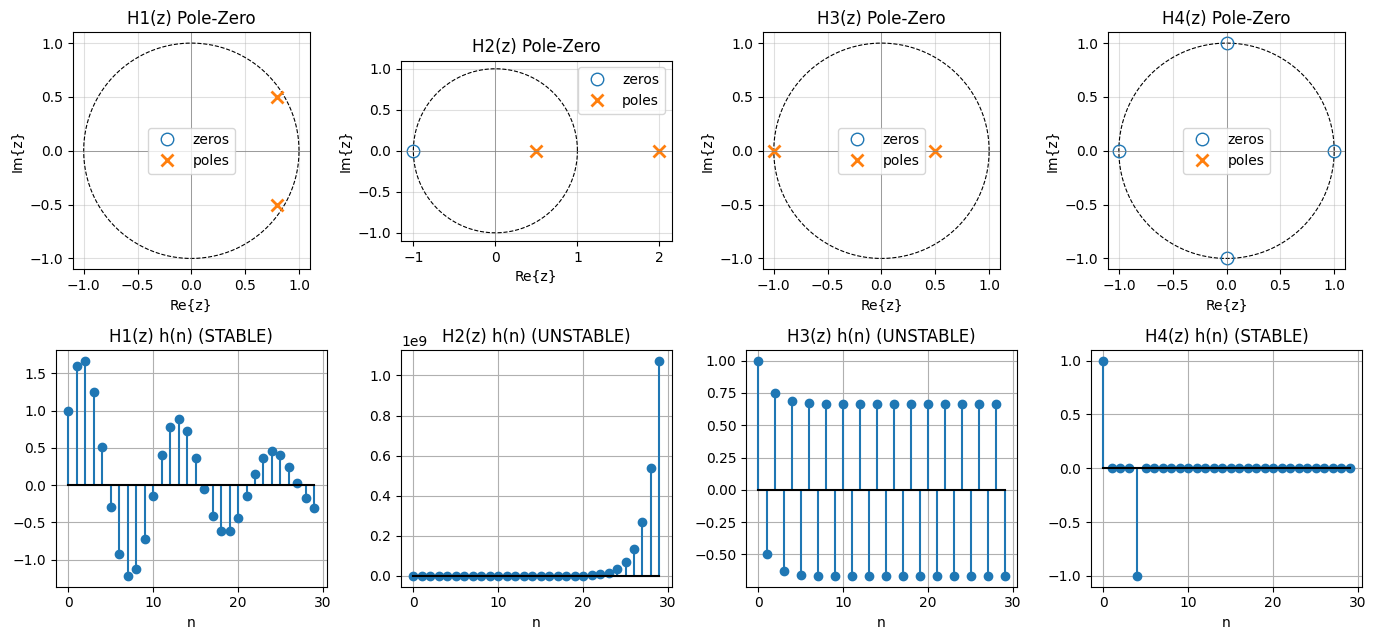

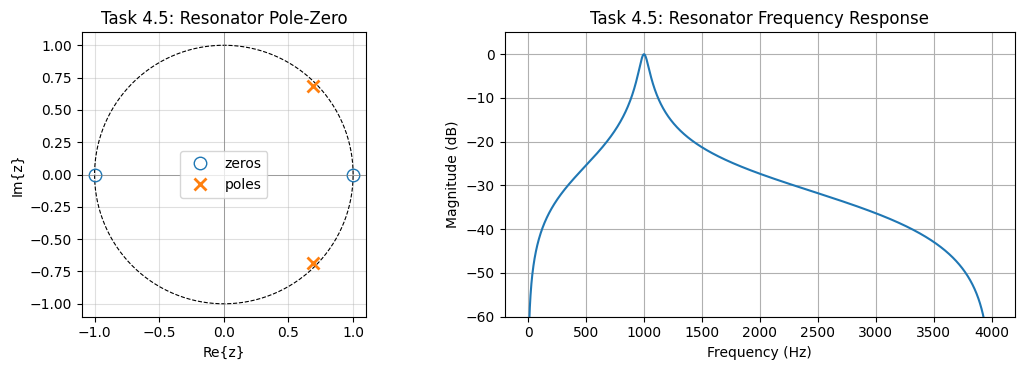

White noise input:


Resonator filtered output (1 kHz pitched whistle/ringing):


In [4]:
# ==========================================
# Task 4.4: Stability of Given Systems
# ==========================================
systems_4 = {
    "H1(z)": ([1], [1, -1.6, 0.89]),
    "H2(z)": ([1, 1], [1, -2.5, 1]),
    "H3(z)": ([1], [1, 0.5, -0.5]),
    "H4(z)": ([1, 0, 0, 0, -1], [1])
}

print("=== Task 4.4: Stability Classification ===")
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
imp30 = np.zeros(30)
imp30[0] = 1.0

for idx, (name, (bs, as_)) in enumerate(systems_4.items()):
    z, p = zplane(bs, as_, axes[0, idx], title=f"{name} Pole-Zero")
    max_p = np.max(np.abs(p)) if len(p) > 0 else 0.0
    is_stable = max_p < 1.0
    status = "STABLE" if is_stable else "UNSTABLE"
    print(f"{name}: poles = {np.round(p, 4)} | max|p| = {max_p:.4f} -> {status}")

    h_sys = signal.lfilter(bs, as_, imp30)
    axes[1, idx].stem(np.arange(30), h_sys, basefmt="k-")
    axes[1, idx].set_title(f"{name} h(n) ({status})")
    axes[1, idx].set_xlabel("n")
    axes[1, idx].grid(True)

plt.tight_layout()
plt.show()


# ==========================================
# Task 4.5: Design a 1 kHz Resonator (fs = 8 kHz)
# ==========================================
fs = 8000
f0 = 1000
r = 0.97
omega0 = 2 * np.pi * f0 / fs  # pi/4 rad

# Zeros at z = +1 and z = -1 -> B(z) = (1 - z^-1)(1 + z^-1) = 1 - z^-2
b_res = [1.0, 0.0, -1.0]
# Poles at r * exp(+-j*omega0) -> A(z) = 1 - 2r*cos(omega0)*z^-1 + r^2*z^-2
a_res = [1.0, -2 * r * np.cos(omega0), r**2]

# Normalize peak gain to 1 (0 dB) at f0
w_res, H_res = signal.freqz(b_res, a_res, worN=2048, fs=fs)
b_res = np.array(b_res) / np.max(np.abs(H_res))
w_res, H_res = signal.freqz(b_res, a_res, worN=2048, fs=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
zplane(b_res, a_res, ax1, title="Task 4.5: Resonator Pole-Zero")
ax2.plot(w_res, 20 * np.log10(np.abs(H_res) + 1e-12))
ax2.set_title("Task 4.5: Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_ylim(-60, 5)
ax2.grid(True)
plt.tight_layout()
plt.show()

# Apply resonator to 2 seconds of white noise and play audio
rng = np.random.default_rng(7)
white_noise = 0.5 * rng.standard_normal(2 * fs)
y_res = signal.lfilter(b_res, a_res, white_noise)
y_res = y_res / np.max(np.abs(y_res)) * 0.8

print("White noise input:")
display(Audio(white_noise, rate=fs))
print("Resonator filtered output (1 kHz pitched whistle/ringing):")
display(Audio(y_res, rate=fs))